In [1]:
# Імпортуємо датасет:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('SouthGermanCredit.asc', sep=r'\s+')


In [6]:
#Аналізуємо датасет на пропуски, дуплікати і тд. :
class DatasetQualityAnalyzer:
    def __init__(self, df: pd.DataFrame):
        self.df = df

    def check_structure(self):

        print(f"String number: {self.df.shape[0]}")
        print(f"Collumns number: {self.df.shape[1]}\n")
        print("Datatypes:")
        print(self.df.dtypes.to_string())
        print("\n")

    def check_missing_and_duplicates(self):
        duplicates = self.df.duplicated().sum()
        print(f"Duplicates: {duplicates}")

        missing = self.df.isnull().sum()
        missing_filtered = missing[missing > 0]

        if missing_filtered.empty:
            print("NaNs are missing from dataset! 👍")
        else:
            print("Number of missing values per column:")
            print(missing_filtered.to_string())
        print("\n")

    def run_full_analysis(self):
        self.check_structure()
        self.check_missing_and_duplicates()

DatasetQualityAnalyzer(df).run_full_analysis()


String number: 1000
Collumns number: 21

Datatypes:
laufkont    int64
laufzeit    int64
moral       int64
verw        int64
hoehe       int64
sparkont    int64
beszeit     int64
rate        int64
famges      int64
buerge      int64
wohnzeit    int64
verm        int64
alter       int64
weitkred    int64
wohn        int64
bishkred    int64
beruf       int64
pers        int64
telef       int64
gastarb     int64
kredit      int64


Duplicates: 0
NaNs are missing from dataset! 👍




In [7]:
# Масштабування ознак
X = df.drop(columns=[df.columns[-1]])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [8]:
#Двомірна репрезентація за допомогою t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

In [9]:
#Тренування моделі 1: K-Means
kmeans = KMeans(n_clusters=2, random_state=42, n_init="auto")
kmeans_labels = kmeans.fit_predict(X_scaled)

In [10]:
#Тренування моделі 2: Agglomerative Clustering
agg_cluster = AgglomerativeClustering(n_clusters=2, metric='euclidean', linkage='ward')
agg_labels = agg_cluster.fit_predict(X_scaled)

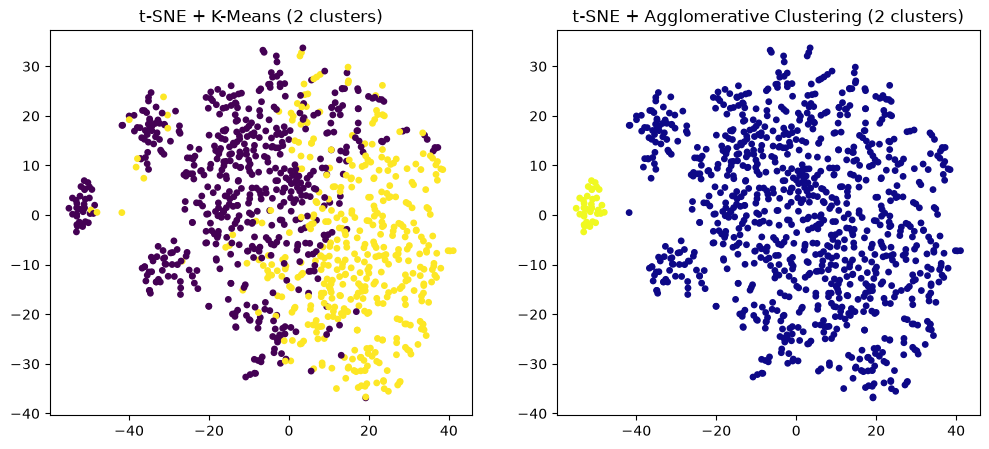

In [11]:
# Візуалізація результатів t-SNE та кластеризації
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_labels, cmap='viridis', s=15)
plt.title("t-SNE + K-Means (2 clusters)")

plt.subplot(1, 2, 2)
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=agg_labels, cmap='plasma', s=15)
plt.title("t-SNE + Agglomerative Clustering (2 clusters)")
plt.show()

In [13]:
#Порівняння результатів показує, що алгоритми по-різному інтерпретують структуру даних на t-SNE проєкції. K-Means виконує глобальний поділ вибірки на дві збалансовані групи з розмитою межею перетину, тоді як Agglomerative Clustering чітко виділяє невеликі відокремлені ділянки даних в окремий кластер, залишаючи решту масиву єдиною структурою.
